# The heat equation
Authors: Anders Logg and Hans Petter Langtangen

Minor modifications by: Jørgen S. Dokken

As a first extension of the Poisson problem from the previous chapter, we consider the time-dependent heat equation, or the time-dependent diffusion equation. This is the natural extension of the Poisson equation describing the stationary distribution of heat in a body to a time-dependent problem. We will see that by discretizing time into small time intervals and applying standard time-stepping methods, we can solve the heat equation by solving a sequence of variational problems, much like the one we encountered for the Poisson equation.

## The PDE problem
The model problem for the time-dependent PDE reads
\begin{align}
    \frac{\partial u}{\partial t}&=\nabla^2 u + f && \text{in } \Omega \times (0, T],\\
    u &= u_D && \text{on } \partial\Omega \times (0,T],\\
    u &= u_0 && \text{at } t=0.
\end{align}

Here $u$ varies with space and time, e.g. $u=u(x,y,t)$ if the spatial domain $\Omega$ is two-dimensional. The source function $f$ and the boundary values $u_D$ may also vary with space and time. The initial condition $u_0$ is a function of space only.

## The variational formulation
A straightforward approach to solving time-dependent PDEs by the finite element method is to first discretize the time derivative by a finite difference approximation, which yields a sequence of stationary problems, and then turn each stationary problem into a variational formulation. 
We will let the superscript $n$ denote a quantity at time $t_n$, where $n$ is an integer counting time levels. For example, $u^n$ means $u$ at time level $n$. The first step of a finite difference discretization in time consists of sampling the PDE at some time  level, for instance $t_{n+1}$
\begin{align}
    \left(\frac{\partial u }{\partial t}\right)^{n+1}= \nabla^2 u^{n+1}+ f^{n+1}.
\end{align}
The time-derivative can be  approximated by a difference quotient. For simplicity and stability reasons, we choose a simple backward difference:
\begin{align}
    \left(\frac{\partial u }{\partial t}\right)^{n+1}\approx \frac{u^{n+1}-u^n}{\Delta t},
\end{align}
where $\Delta t$ is the time discretization parameter. Inserting the latter expression into our equation at time step $n+1$ yields
\begin{align}
    \frac{u^{n+1}-u^n}{\Delta t}= \nabla^2 u^{n+1}+ f^{n+1}.
\end{align}
This is our time-discrete version of the heat equation. It is called a *backward Euler* or a *implicit Euler* discretization.

We reorder the equation such that the left-hand side contains the terms with only the unknown $u^{n+1}$ and right-hand side contains only computed terms. The resulting equation is a sequence of stationary problems for $u^{n+1}$, assuming $u^{n}$ is known from the previous time step:
\begin{align}
    u^0&=u_0 &&\\
    u^{n+1}-\Delta t \nabla^2 u^{n+1}&= u^{n} + \Delta t f^{n+1}, && n = 0,1,2,\dots
\end{align}
Given $u_0$, we can solve for $u^0, u^1, u^2$ and so on.

We then in turn use the finite element method. This means that we have to turn the equation into its weak formulation. We multiply by the test-function of $v\in \hat{V}$ and integrate second-order derivatives by parts. We now introduce the symbol $u$ for $u^{n+1}$ and we write the resulting weak formulation as

\begin{align}
    a(u,v)&=L_{n+1}(v),
\end{align}
where 
\begin{align}
    a(u,v)&=\int_{\Omega}(uv + \Delta t \nabla u \cdot \nabla v )~\mathrm{d} x\\
    L_{n+1}(v)&=\int_{\Omega} (u^n+\Delta t f^{n+1}) \cdot v~\mathrm{d} x.
\end{align}


## Projection or interpolation of the initial condition
In addition to the variational problem to be solved in each  time step, we also need to approximate the initial condition. This equation can also be turned into a variational problem
\begin{align}
    a_0(u,v)&=L_0(V),
\end{align}
with 
\begin{align}
    a_0(u,v)&=\int_{\Omega}uv~\mathrm{d} x,\\
    L_0(v)&=\int_{\Omega}u_0v~\mathrm{d} x.
\end{align}
When solving this variational problem $u^0$ becomes the $L^2$-projection of the given initial value $u_0$ into the finite element space. 

The alternative is to construct $u^0$ by just interpolating the initial value $u_0$. We covered how to use interpolation in DOLFINx in the {doc}`membrane chapter <../chapter1/membrane_code>`.

We can use DOLFINx to either project or interpolate the initial condition. The most common choice is to use a projection, which computes an approximation to $u_0$. However, in some applications where we want to verify the code by reproducing exact solutions, one must use interpolation. In this chapter, we will use such a problem.

In [25]:
import numpy as np

import ufl
from ufl import ds, dx, grad, inner

from dolfinx import fem, io, mesh, plot, log
from dolfinx.io import gmshio # to import gmsh functions
from dolfinx import geometry # to define the line plot
from dolfinx import default_scalar_type
import dolfinx.fem.petsc

from mpi4py import MPI

from petsc4py.PETSc import ScalarType

import matplotlib.pyplot as plt
import matplotlib as mpl


In [26]:
class Thermal:
    def __init__(self, mesh_file, rank=0, gdim=3):
        """
        Initialize the Thermal class with the mesh file.

        Parameters:
        mesh_file (str): Path to the mesh file.
        rank (int): Rank of the process (default is 0).
        gdim (int): Geometric dimension of the mesh (default is 3).
        """
        self.mesh_file = mesh_file
        self.rank = rank
        self.gdim = gdim
        self._read_mesh()
        self._setup_function_space()
        self._initialize_functions()

    def _read_mesh(self):
        """
        Read the mesh and facet tags from the specified mesh file.
        """
        try:
            self.domain, self.tags, self.ft = gmshio.read_from_msh(self.mesh_file, MPI.COMM_WORLD, rank=self.rank, gdim=self.gdim)
            self.tdim = self.domain.topology.dim
            self.fdim = self.tdim - 1
            self.domain.topology.create_connectivity(self.fdim, self.tdim)
        except Exception as e:
            raise ValueError(f"Error reading mesh file {self.mesh_file}: {e}")

    def _setup_function_space(self):
        """
        Set up the function space for the problem.
        """
        self.V = fem.functionspace(self.domain, ("Lagrange", 1))
        self.W = fem.functionspace(self.domain, ("Lagrange", 1, (self.domain.geometry.dim,)))

    def _initialize_functions(self):
        """
        Initialize trial and test functions.
        """
        self.u = ufl.TrialFunction(self.V)
        self.v = ufl.TestFunction(self.V)

    def parameters(self, k):
        """
        Set material and physical parameters.

        Parameters:
        k (float): thermal conductivity.

        """
        self.k = k
        self.f = fem.Constant(self.domain, ScalarType(100.0))

    def boundary_conditions(self, internal_temperature, outer_temperature):
        """
        Define and set the boundary conditions.
        """
        
        # Locate dofs for Dirichlet boundary conditions
        self.dofs_D_top     = fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(4))
        self.dofs_D_bottom  = fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(1))
        self.dofs_D_outer   = fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(3))
        self.dofs_D_inner   = fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(2))

        # Dirichlet boundary conditions
        # self.bc_top     = fem.dirichletbc(ScalarType(400), dofs=self.dofs_D_top, V=self.V)
        # self.bc_bottom  = fem.dirichletbc(ScalarType(400), dofs=self.dofs_D_bottom, V=self.V)
        self.bc_outer   = fem.dirichletbc(400.0, dofs=self.dofs_D_outer, V=self.V)
        # self.bc_inner   = fem.dirichletbc(ScalarType(410), dofs=self.dofs_D_inner, V=self.V)

        self.bc = [self.bc_outer]

        # Boundary conditions
        self.normal = ufl.FacetNormal(self.domain)
        # self.temperature_inner = fem.Constant(self.domain, default_scalar_type(internal_temperature))
        # self.temperature_outer = fem.Constant(self.domain, default_scalar_type(outer_temperature))

    def timeLoop(self, dt):
        self.dt = dt

    def assemble_system(self):
        """
        Assemble the system
        """
        self.a = ufl.dot(ufl.grad(self.u), ufl.grad(self.v)) * ufl.dx
        self.L = self.f * self.v * ufl.dx

    def solve(self):
        """
        Solve the thermal problem.
        """
        
        # problem = dolfinx.fem.petsc.LinearProblem(self.a, self.L, bcs=[self.temperature_inner, self.temperature_outer], petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
        self.problem = fem.petsc.LinearProblem(self.a, self.L, bcs=self.bc, petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
        self.temperature = self.problem.solve()

    def get_results(self):
        """
        Get the computed displacement, stress, and strain fields.

        Returns:
        temperature (Function): The temperature field.
        """
        return self.temperature
    
    def gradient(self):
        # Approximate gradient
        dg = dolfinx.fem.functionspace(self.domain,("Lagrange", 1, (self.domain.geometry.dim,)))
        grad_uh = dolfinx.fem.Function(dg)

        grad_u_expr_x = fem.Expression(grad(self.temperature)[0], dg.element.interpolation_points()) # d/dx
        grad_u_expr_y = fem.Expression(grad(self.temperature)[1], dg.element.interpolation_points()) # d/dy

        # Extract gradient
        grad_uh.interpolate(grad_u_expr_x)
        return grad_uh
    
    def linePlot(self, xi, xf, yi, yf, N):
        points = np.zeros((3, N))

        points[0] = np.linspace(xi, xf, N)
        points[1] = np.linspace(yi, yf, N)

        u_values = []
        cells = []
        points_on_proc = []

        bb_tree = self.domain.geometry.BoundingBoxTree(self.domain, self.tdim)

        cell_candidates = geometry.compute_collisions(bb_tree, points.T)
        colliding_cells = geometry.compute_colliding_cells(self.domain, cell_candidates, points.T)

        for i, point in enumerate(points.T):
            if len(colliding_cells.links(i))>0:
                points_on_proc.append(point)
                cells.append(colliding_cells.links(i)[0])
                
        points_on_proc = np.array(points_on_proc, dtype=np.float64)
        u_values = self.solution.eval(points_on_proc, cells)
        
        return points_on_proc, u_values

In [27]:
problem = Thermal(mesh_file='../../mesh/cylindrical_shell_structured.msh')

thermal_conductivity = 15

problem.parameters(k=thermal_conductivity)
problem.boundary_conditions(internal_temperature=500, outer_temperature=400)
problem.assemble_system()
problem.solve()
temperature = problem.get_results()



Info    : Reading '../../mesh/cylindrical_shell_structured.msh'...
Info    : 73 entities
Info    : 20808 nodes
Info    : 22984 elements
Info    : Done reading '../../mesh/cylindrical_shell_structured.msh'


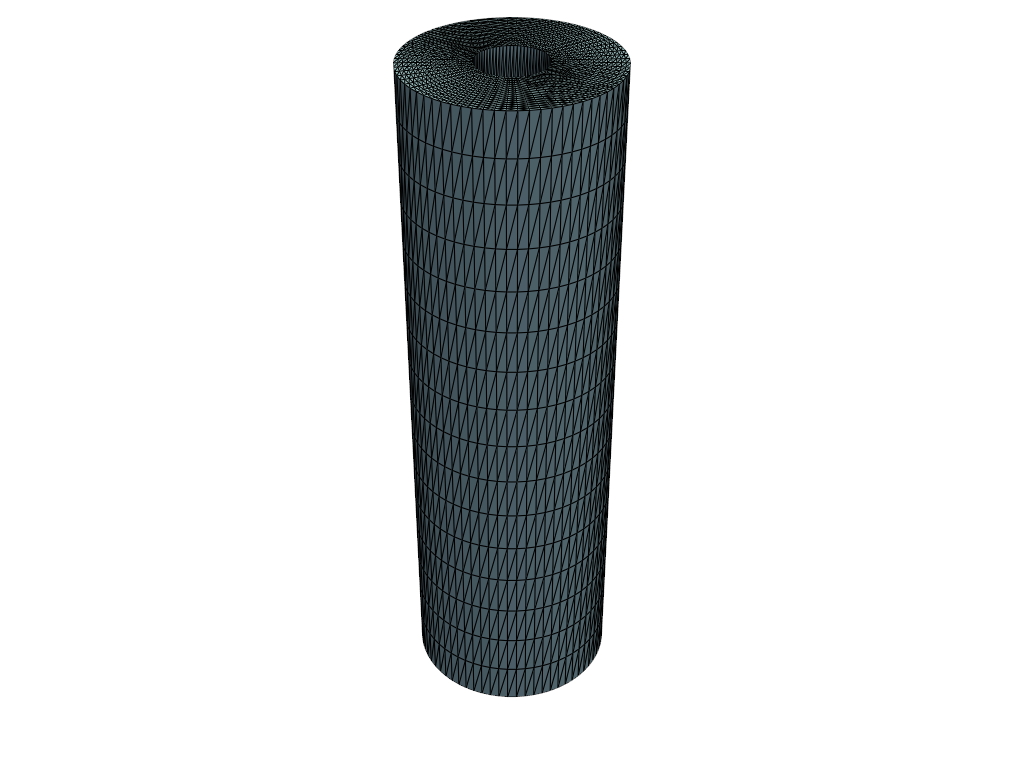

In [28]:
import pyvista
from dolfinx import plot

pyvista.start_xvfb()
problem.domain.topology.create_connectivity(problem.tdim, problem.tdim)
topology, cell_types, geometry = plot.vtk_mesh(problem.domain, problem.tdim)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)

plotter = pyvista.Plotter()
plotter.add_mesh(grid, show_edges=True)
plotter.view_isometric()
if not pyvista.OFF_SCREEN:
    plotter.show()
else:
    figure = plotter.screenshot("fundamentals_mesh.png")

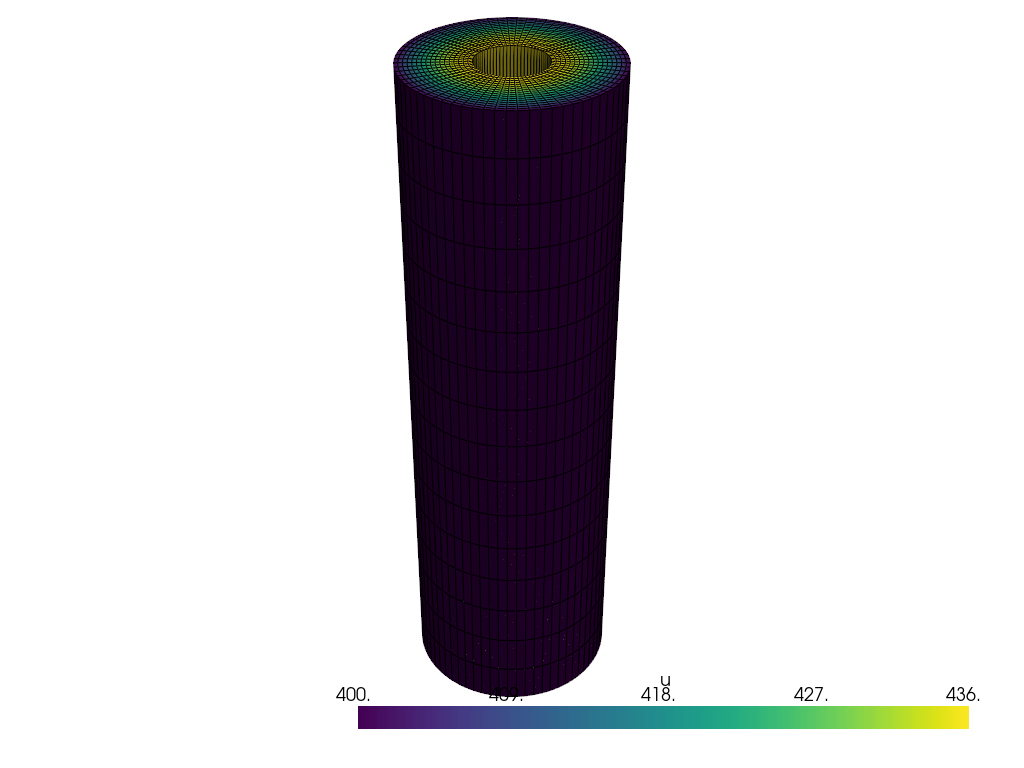

In [29]:
u_topology, u_cell_types, u_geometry = plot.vtk_mesh(problem.V)

u_grid = pyvista.UnstructuredGrid(u_topology, u_cell_types, u_geometry)
u_grid.point_data["u"] = temperature.x.array.real
u_grid.set_active_scalars("u")
u_plotter = pyvista.Plotter()
u_plotter.add_mesh(u_grid, show_edges=True)
u_plotter.view_isometric()
if not pyvista.OFF_SCREEN:
    u_plotter.show()


In [30]:
# N = 101
# points, u_lineplot = problem.linePlot(0.85, 0.85, 0.0, 1.5, N)

# # 2D plot
# u_topology, u_cell_types, u_geometry = plot.vtk_mesh(problem.V)

# u_grid = pyvista.UnstructuredGrid(u_topology, u_cell_types, u_geometry)
# u_grid.point_data["u"] = uh.x.array.real
# u_grid.set_active_scalars("u")
# u_plotter = pyvista.Plotter()
# u_plotter.add_mesh(u_grid, show_edges=True)
# u_plotter.view_xy()
# if not pyvista.OFF_SCREEN:
#     u_plotter.show()

# # Line plot
# fig = plt.figure()
# plt.plot(points[:,1], u_lineplot, "k", linewidth=2, label="$u_h$")
# plt.grid(True)
# plt.xlabel("y")
# plt.legend()

In [31]:
# # 2D plot
# u_topology, u_cell_types, u_geometry = plot.vtk_mesh(problem.V)

# u_grid = pyvista.UnstructuredGrid(u_topology, u_cell_types, u_geometry)
# u_grid.point_data["u"] = problem.gradient().sub(0).collapse().y.array.real
# u_grid.set_active_scalars("u")
# u_plotter = pyvista.Plotter()
# u_plotter.add_mesh(u_grid, show_edges=True)
# u_plotter.view_xy()
# if not pyvista.OFF_SCREEN:
#     u_plotter.show()

# # The solution can be written to a file, and visualize it with ParaView or VisIt:
# with io.XDMFFile(problem.domain.comm, "out_poisson/poisson.xdmf", "w") as file:
#     file.write_mesh(problem.domain)
#     file.write_function(problem.gradient())
